In [1]:
%env  WORKDIR=/tmp/vault-gcp

env: WORKDIR=/tmp/vault-gcp


In [2]:
import os
from dotenv import load_dotenv

load_dotenv("../config.env")

VAULT_TOKEN = os.getenv('VAULT_TOKEN')
VAULT_ADDR = os.getenv('VAULT_ADDR')

In [3]:
! eval $(terraform output -state=../1_Platform_Deployment/terraform.tfstate -raw configure_kubectl_cluster_primary)

Fetching cluster endpoint and auth data.
kubeconfig entry generated for europe-southwest1-autopilot-cluster5m7e.


# [Database Secret Engine](https://developer.hashicorp.com/vault/tutorials/db-credentials/database-secrets)

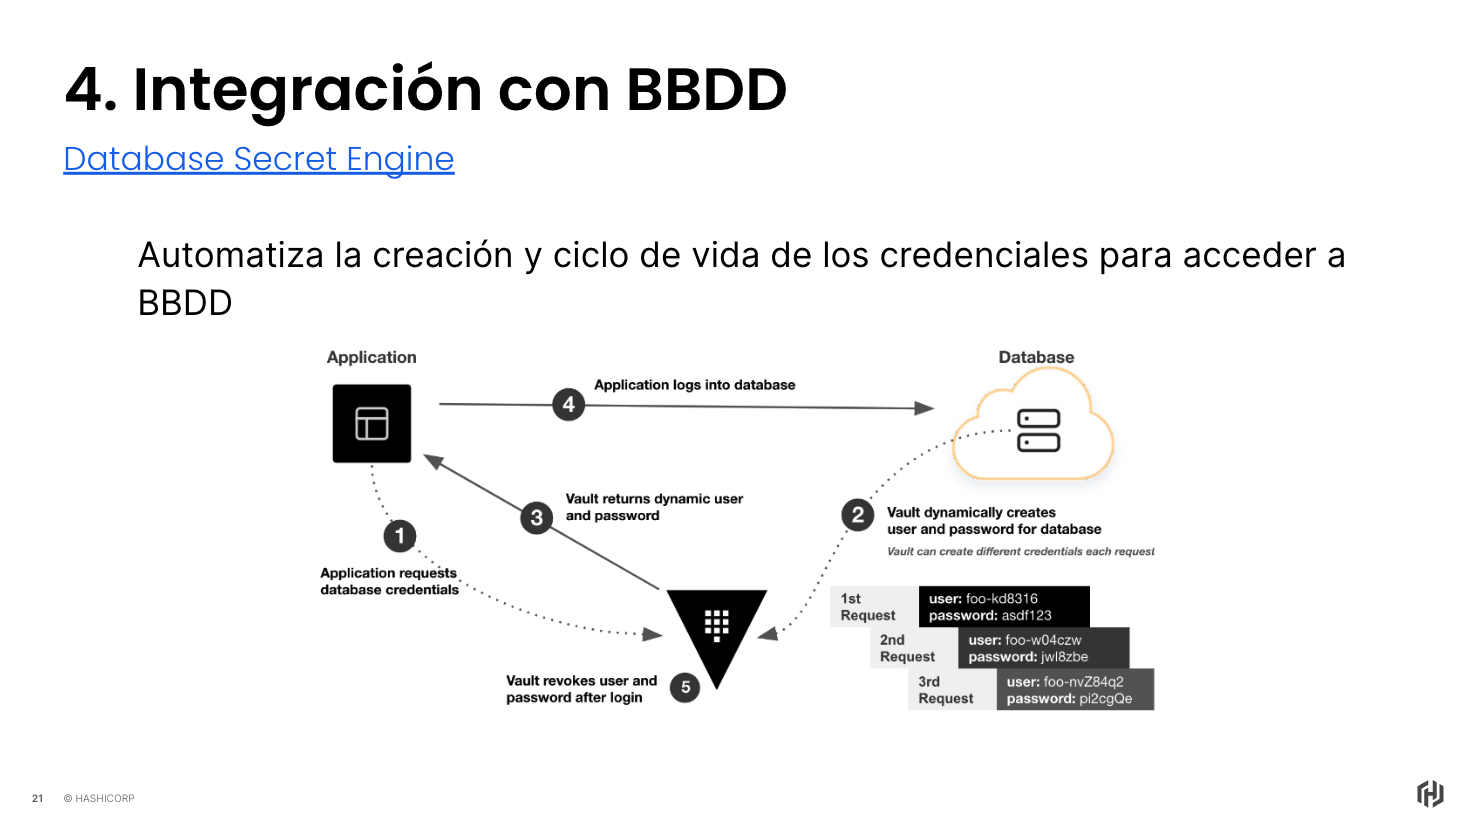

## Step 1: Install PostgreSQL

In [4]:
%%bash
# https://cloud.google.com/kubernetes-engine/docs/tutorials/stateful-workloads/zalando

helm repo add postgres-operator-charts https://opensource.zalando.com/postgres-operator/charts/postgres-operator
kubectl create ns postgres
kubectl create ns zalando
helm install postgres-operator postgres-operator-charts/postgres-operator -n zalando \
    --set configKubernetes.enable_pod_antiaffinity=true \
    --set configKubernetes.pod_antiaffinity_preferred_during_scheduling=true \
    --set configKubernetes.pod_antiaffinity_topology_key="topology.kubernetes.io/zone" \
    --set configKubernetes.spilo_fsgroup="103"


"postgres-operator-charts" already exists with the same configuration, skipping
namespace/postgres created
namespace/zalando created
NAME: postgres-operator
LAST DEPLOYED: Mon Jun 30 19:58:50 2025
NAMESPACE: zalando
STATUS: deployed
REVISION: 1
TEST SUITE: None
NOTES:
To verify that postgres-operator has started, run:

  kubectl --namespace=zalando get pods -l "app.kubernetes.io/name=postgres-operator"


In [8]:
! kubectl --namespace=zalando get pods -l "app.kubernetes.io/name=postgres-operator"

NAME                                 READY   STATUS    RESTARTS   AGE
postgres-operator-569b787bd9-bhgp2   1/1     Running   0          2m1s


In [9]:
! kubectl apply -n postgres -f postgres.yaml

postgresql.acid.zalan.do/my-cluster created


In [10]:
! kubectl wait pods -l cluster-name=my-cluster  --for condition=Ready --timeout=300s -n postgres

pod/my-cluster-0 condition met


In [11]:
%%bash
curl https://raw.githubusercontent.com/helm/helm/main/scripts/get-helm-3 | bash
helm repo add bitnami https://charts.bitnami.com/bitnami
helm repo update

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 11913  100 11913    0     0  55125      0 --:--:-- --:--:-- --:--:-- 55152


Verifying checksum... Done.
Preparing to install helm into /usr/local/bin


sudo: a terminal is required to read the password; either use the -S option to read from standard input or configure an askpass helper
sudo: a password is required


Failed to install helm
	For support, go to https://github.com/helm/helm.
"bitnami" already exists with the same configuration, skipping
Hang tight while we grab the latest from your chart repositories...
...Successfully got an update from the "postgres-operator-charts" chart repository
...Successfully got an update from the "vault" chart repository
...Successfully got an update from the "hashicorp" chart repository
...Successfully got an update from the "secrets-store-csi-driver" chart repository
...Successfully got an update from the "jetstack" chart repository
...Successfully got an update from the "minio" chart repository
...Successfully got an update from the "jaeger-all-in-one" chart repository
...Successfully got an update from the "jaegertracing" chart repository
...Successfully got an update from the "datadog" chart repository
...Successfully got an update from the "signoz" chart repository
...Successfully got an update from the "gitlab" chart repository
...Successfully got an 

In [12]:
%%bash
username=$(kubectl get secrets -n postgres mydatabaseowner.my-cluster.credentials.postgresql.acid.zalan.do -o json | jq -r .data.username | base64 -d)
echo "${username/%/}"

mydatabaseowner


In [13]:
%%bash
password=$(kubectl get secrets -n postgres mydatabaseowner.my-cluster.credentials.postgresql.acid.zalan.do -o json | jq -r .data.password | base64 -d)
echo "${password/%/}"

nSMnbAHXmpndbvFCtG3QOf9u3ZC9dvpD83POV1xEcnNDgWnE2oWDILggemp35Ky5


### Create a role in the database that will be used by Vault Dynamic Role

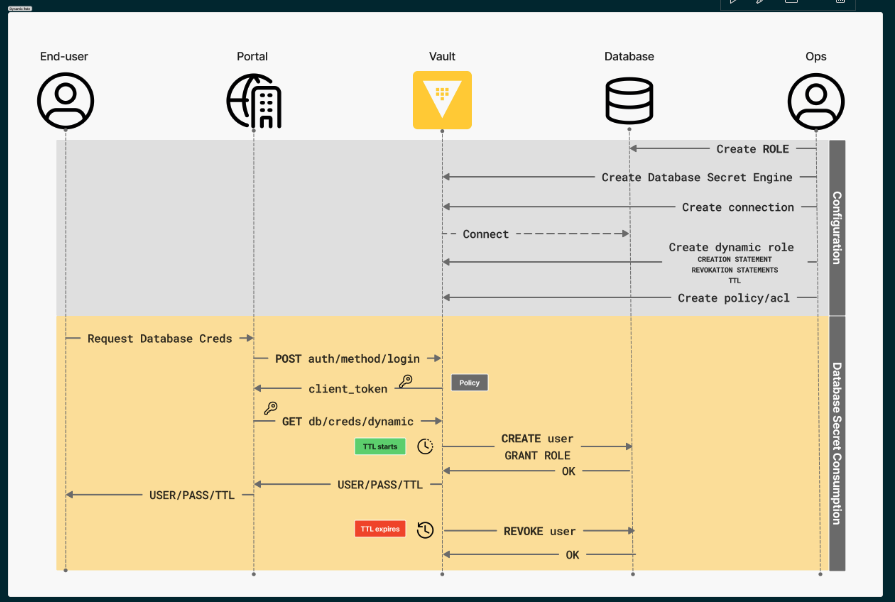

In [14]:
%%bash
username=$(kubectl get secrets -n postgres postgres.my-cluster.credentials.postgresql.acid.zalan.do  -o json | jq -r .data.username | base64 -d)
export USER=$(echo "${username/%/}")
password=$(kubectl get secrets -n postgres postgres.my-cluster.credentials.postgresql.acid.zalan.do  -o json | jq -r .data.password | base64 -d)
export PASSWORD=$(echo "${password/%/}")

echo "kubectl exec -i -t my-cluster-0 -n postgres -- /bin/bash"
echo "export PGPASSWORD=${PASSWORD}; psql --host 127.0.0.1 -U ${USER} -c 'CREATE ROLE \"ro\" NOINHERIT;'"
echo "export PGPASSWORD=${PASSWORD}; psql --host 127.0.0.1 -U ${USER} -c 'GRANT SELECT ON ALL TABLES IN SCHEMA public TO \"ro\";'"


kubectl exec -i -t my-cluster-0 -n postgres -- /bin/bash
export PGPASSWORD=Nrb3swqXWZkbeMYKSGyj5iKbUz7o4ew8OwQlvOpKQKv3x40CLGyxmPTDfo56zZN8; psql --host 127.0.0.1 -U postgres -c 'CREATE ROLE "ro" NOINHERIT;'
export PGPASSWORD=Nrb3swqXWZkbeMYKSGyj5iKbUz7o4ew8OwQlvOpKQKv3x40CLGyxmPTDfo56zZN8; psql --host 127.0.0.1 -U postgres -c 'GRANT SELECT ON ALL TABLES IN SCHEMA public TO "ro";'


## Enable the database secret engine

In [15]:
%%bash
export POSTGRES_URL=my-cluster.postgres.svc.cluster.local

username=$(kubectl get secrets -n postgres mydatabaseowner.my-cluster.credentials.postgresql.acid.zalan.do -o json | jq -r .data.username | base64 -d)
export USER=$(echo "${username/%/}")
password=$(kubectl get secrets -n postgres mydatabaseowner.my-cluster.credentials.postgresql.acid.zalan.do -o json | jq -r .data.password | base64 -d)
export PASSWORD=$(echo "${password/%/}")

# Enable engine
vault secrets enable -local database  # We are going to use a local database in this example, since the PR cluster does not have access to the database

# Configure the database secrets engine with the connection credentials for the Postgres database.
vault write database/config/postgresql \
     plugin_name=postgresql-database-plugin \
     connection_url="postgresql://{{username}}:{{password}}@$POSTGRES_URL/postgres?sslmode=require" \
     allowed_roles=* \
     username=$USER \
     password=$PASSWORD

Success! Enabled the database secrets engine at: database/
Success! Data written to: database/config/postgresql


## Create a role in Vault (for readonly access named `readonly`)

In [16]:
%%bash
cat > ${WORKDIR}/readonly.sql <<EOF
CREATE ROLE "{{name}}" WITH LOGIN PASSWORD '{{password}}' VALID UNTIL '{{expiration}}' INHERIT;
GRANT ro TO "{{name}}";
EOF

In [17]:
%%bash
cat > ${WORKDIR}/readonly_revoke.sql <<EOF
REVOKE ALL ON ALL TABLES IN SCHEMA public FROM "{{name}}";
REVOKE ALL PRIVILEGES ON ALL SEQUENCES IN SCHEMA public FROM "{{name}}";
REVOKE ALL PRIVILEGES ON ALL FUNCTIONS IN SCHEMA public FROM "{{name}}";
DROP ROLE IF EXISTS "{{name}}";
EOF

In [18]:
%%bash
vault write database/roles/readonly \
      db_name=postgresql \
      creation_statements=@${WORKDIR}/readonly.sql \
      revokation_statements=@${WORKDIR}/readonly_revoke.sql \
      default_ttl=120s \
      max_ttl=24h

Success! Data written to: database/roles/readonly


# Request Credentials

### Via CLI

In [20]:
! vault read database/creds/readonly

Key                Value
---                -----
lease_id           database/creds/readonly/JvzFDetdvDnNkB2AaNO4exjH
lease_duration     2m
lease_renewable    true
password           SaeACG1wtqypOl0NT0L-
username           v-root-readonly-3H9shfSy34iiyxcyFu5N-1751306785


### Via API

In [21]:
! curl -k --header "X-Vault-Token: $VAULT_TOKEN" --silent --request GET $VAULT_ADDR/v1/database/creds/readonly | jq -r .

{
  "request_id": "200056e2-67b2-6223-09d4-066cf25c4b21",
  "lease_id": "database/creds/readonly/8sXb0zEcT6ooWX8SVLEYTBkH",
  "renewable": true,
  "lease_duration": 120,
  "data": {
    "password": "0CLgPdURMN-Va7wvhItx",
    "username": "v-root-readonly-P2zVHyQzTw2FpPeFyIgw-1751306788"
  },
  "wrap_info": null,
  "warnings": null,
  "auth": null,
  "mount_type": "database"
}


In [22]:
%%bash
password=$(kubectl get secrets -n postgres postgres.my-cluster.credentials.postgresql.acid.zalan.do  -o json | jq -r .data.password | base64 -d)
export PASSWORD=$(echo "${password/%/}")

echo "kubectl exec -i -t my-cluster-0 -n postgres -- /bin/bash"

echo "export PGPASSWORD=${PASSWORD}; psql --host 127.0.0.1 -U postgres -c 'SELECT usename, valuntil FROM pg_user;'"


kubectl exec -i -t my-cluster-0 -n postgres -- /bin/bash
export PGPASSWORD=Nrb3swqXWZkbeMYKSGyj5iKbUz7o4ew8OwQlvOpKQKv3x40CLGyxmPTDfo56zZN8; psql --host 127.0.0.1 -U postgres -c 'SELECT usename, valuntil FROM pg_user;'


## Revoke Credentials

### Check leases in Vault

In [23]:
! vault list sys/leases/lookup/database/creds/readonly

Keys
----
8sXb0zEcT6ooWX8SVLEYTBkH
JvzFDetdvDnNkB2AaNO4exjH


### Revoke individual token (1st from the list)

In [ ]:
%%bash
export LEASE=$(vault list -format=json sys/leases/lookup/database/creds/readonly | jq -r .[0])
vault lease revoke database/creds/readonly/$LEASE

### Check leases again

In [ ]:
! vault list sys/leases/lookup/database/creds/readonly

### Revoke all leases

In [ ]:
! vault lease revoke -prefix database/creds/readonly

### Verify roles in database

In [ ]:
%%bash
password=$(kubectl get secrets -n postgres postgres.my-cluster.credentials.postgresql.acid.zalan.do  -o json | jq -r .data.password | base64 -d)
export PASSWORD=$(echo "${password/%/}")

echo "kubectl exec -i -t my-cluster-0 -n postgres -- /bin/bash"

echo "export PGPASSWORD=${PASSWORD}; psql --host 127.0.0.1 -U postgres -c 'SELECT usename, valuntil FROM pg_user;'"


## Static Role

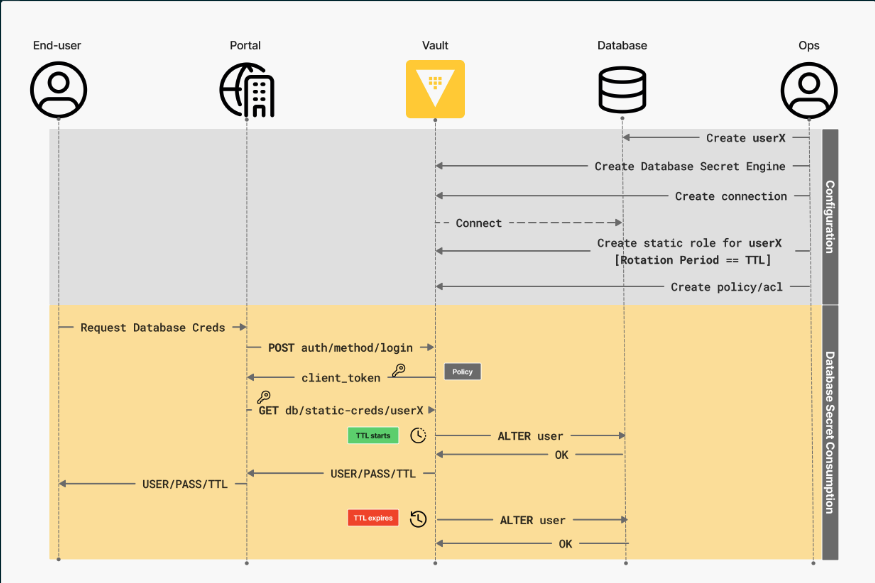

In [24]:
%%bash
# First create role in database
password=$(kubectl get secrets -n postgres postgres.my-cluster.credentials.postgresql.acid.zalan.do  -o json | jq -r .data.password | base64 -d)
export PASSWORD=$(echo "${password/%/}")
# Create role in database
kubectl exec -i -t my-cluster-0 -n postgres -- \
  sh -c "PGPASSWORD='${PASSWORD}' psql --host 127.0.0.1 -U postgres -c \"CREATE ROLE dba WITH LOGIN PASSWORD 'secure_password' SUPERUSER;\""

Defaulted container "postgres" out of: postgres, exporter
Unable to use a TTY - input is not a terminal or the right kind of file


CREATE ROLE


In [26]:
%%bash
vault write database/static-roles/static \
      db_name=postgresql \
      rotation_statements="ALTER USER \"dba\" WITH PASSWORD '{{password}}';" \
      username="dba" \
      rotation_period="120s"
      # skip_import_rotation=false \


In [27]:
! vault read -format=json database/static-creds/static 

{
  "request_id": "13976c2b-ce18-b670-86fb-66d006ff470b",
  "lease_id": "",
  "lease_duration": 0,
  "renewable": false,
  "data": {
    "last_vault_rotation": "2025-06-30T18:07:48.11947695Z",
    "password": "a-n77tGR7q--b7wx5KDH",
    "rotation_period": 120,
    "ttl": 118,
    "username": "dba"
  },
  "warnings": null
}


In [28]:
! sleep 5 && vault read -format=json database/static-creds/static 

{
  "request_id": "485d5bbb-a10c-bb80-578a-86b9dff198fd",
  "lease_id": "",
  "lease_duration": 0,
  "renewable": false,
  "data": {
    "last_vault_rotation": "2025-06-30T18:07:48.11947695Z",
    "password": "a-n77tGR7q--b7wx5KDH",
    "rotation_period": 120,
    "ttl": 111,
    "username": "dba"
  },
  "warnings": null
}


In [29]:
! vault write -f -format=json database/rotate-role/static  \
    && vault read -format=json database/static-creds/static 

{
  "request_id": "d8936475-cf77-51f6-4118-ada8cbf6b0be",
  "lease_id": "",
  "lease_duration": 0,
  "renewable": false,
  "data": {
    "last_vault_rotation": "2025-06-30T18:07:59.873302229Z",
    "password": "VPc-qc5ZBzAzRSvJ22gn",
    "rotation_period": 120,
    "ttl": 120,
    "username": "dba"
  },
  "warnings": null
}


In [30]:
%%bash
# RETRIEVE ADMINISTRATIVE POSTGRES CREDENTIALS
export USERNAME="dba"
export PASSWORD=$(vault read -format=json database/static-creds/static | jq -r .data.password)

# Create role in database
kubectl exec -i -t my-cluster-0 -n postgres  -- \
  sh -c "PGPASSWORD='${PASSWORD}' psql --host 127.0.0.1 -U ${USERNAME} -d postgres -c '\du'"

Defaulted container "postgres" out of: postgres, exporter
Unable to use a TTY - input is not a terminal or the right kind of file


                                                                   List of roles
                    Role name                    |                         Attributes                         |              Member of              
-------------------------------------------------+------------------------------------------------------------+-------------------------------------
 admin                                           | Create DB, Cannot login                                    | {cron_admin,mydatabaseowner,myuser}
 cron_admin                                      | Cannot login                                               | {}
 dba                                             | Superuser                                                  | {}
 mydatabaseowner                                 | Superuser, Create DB                                       | {}
 myuser                                          |                                                            | {}
 postgres    

## Rotate Root password

In [3]:
! vault write -force database/rotate-root/postgresql

Success! Data written to: database/rotate-root/postgresql


In [ ]:
# In the terminal
psql --host 127.0.0.1 -U postgres
****
psql: error: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "postgres"

## Clean up

In [7]:
%%bash
vault lease revoke -prefix database/creds/readonly
vault secrets disable database
kubectl delete ns postgres --ignore-not-found
kubectl delete ns zalando --ignore-not-found

All revocation operations queued successfully!
Success! Disabled the secrets engine (if it existed) at: database/
namespace "postgres" deleted
namespace "zalando" deleted
